# Selected CNN learning curves and raw signal tracing

Exploratory follow-up to Notebook 10. No training, model selection, threshold repair, or exclusions are performed. Saved primary CNN settings, calibration histories and raw PhysioNet files are inspected. New diagnostics go into a fresh timestamped report directory; source notebooks retain no outputs. Identities remain unverified; findings do not establish clinical validity.

In [1]:
import hashlib
import json
from datetime import UTC, datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import wfdb
from IPython.display import display
from scipy.signal import butter, sosfiltfilt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
RUN = ROOT / "data/processed/portfolio-v2/plan001-real-20261108"
R = RUN / "full/real-20261109-v1/results"
PHASE1 = ROOT / "data/processed/phase1"
RAW = ROOT / "data/raw/apnea-ecg-1.0.0"
OUT = ROOT / "reports/portfolio-v2/cnn-curves-raw" / datetime.now(UTC).strftime("%Y%m%dT%H%M%S%fZ")
OUT.mkdir(parents=True, exist_ok=False)
manifest = json.loads((R / "manifest.json").read_text())
for name, expected in manifest["artifacts"].items():
    assert hashlib.sha256((R / name).read_bytes()).hexdigest() == expected, name
phase1 = json.loads((PHASE1 / "manifest.json").read_text())
config = phase1["config"]
cohort = pd.read_parquet(RUN / "protocol/cohort.parquet").reset_index(drop=True)
windows = pd.read_parquet(PHASE1 / "windows.parquet")
history = pd.read_parquet(R / "training_history.parquet")
choices = pd.DataFrame(json.loads((R / "selected_configurations.json").read_text()))
selected = choices.query("analysis == 'tuned' and model == 'cnn' and seed == 67")
freeze = json.loads((RUN / "freeze/payload.json").read_text())
# The freeze pins waveform artifacts, not the historical Phase 1 manifest.
# Verify those artifacts directly before trusting their raw/filtered arrays.
for name, expected in freeze["identity"]["input_hashes"].items():
    if name.startswith("waveforms/"):
        assert hashlib.sha256((PHASE1 / name).read_bytes()).hexdigest() == expected
print("Output:", OUT)

Output: <project-root>/reports/portfolio-v2/cnn-curves-raw/20261110T025126662499Z


## Selected calibration histories

For each selected candidate and inner fold, reproduce the saved stopping rule: unweighted BCE must improve by more than 0.0001; eight non-improving epochs trigger stopping. Best calibration weights are not used directly for scoring: training is restarted on all inner-fit data for the selected epoch count. This makes short calibration schedules consequential. Weighted training BCE and unweighted stopping BCE are not always directly comparable.

Plots mark selected epochs. Loss trajectories diagnose behavior of the frozen rule; they cannot show what would happen after more training without a new experiment.

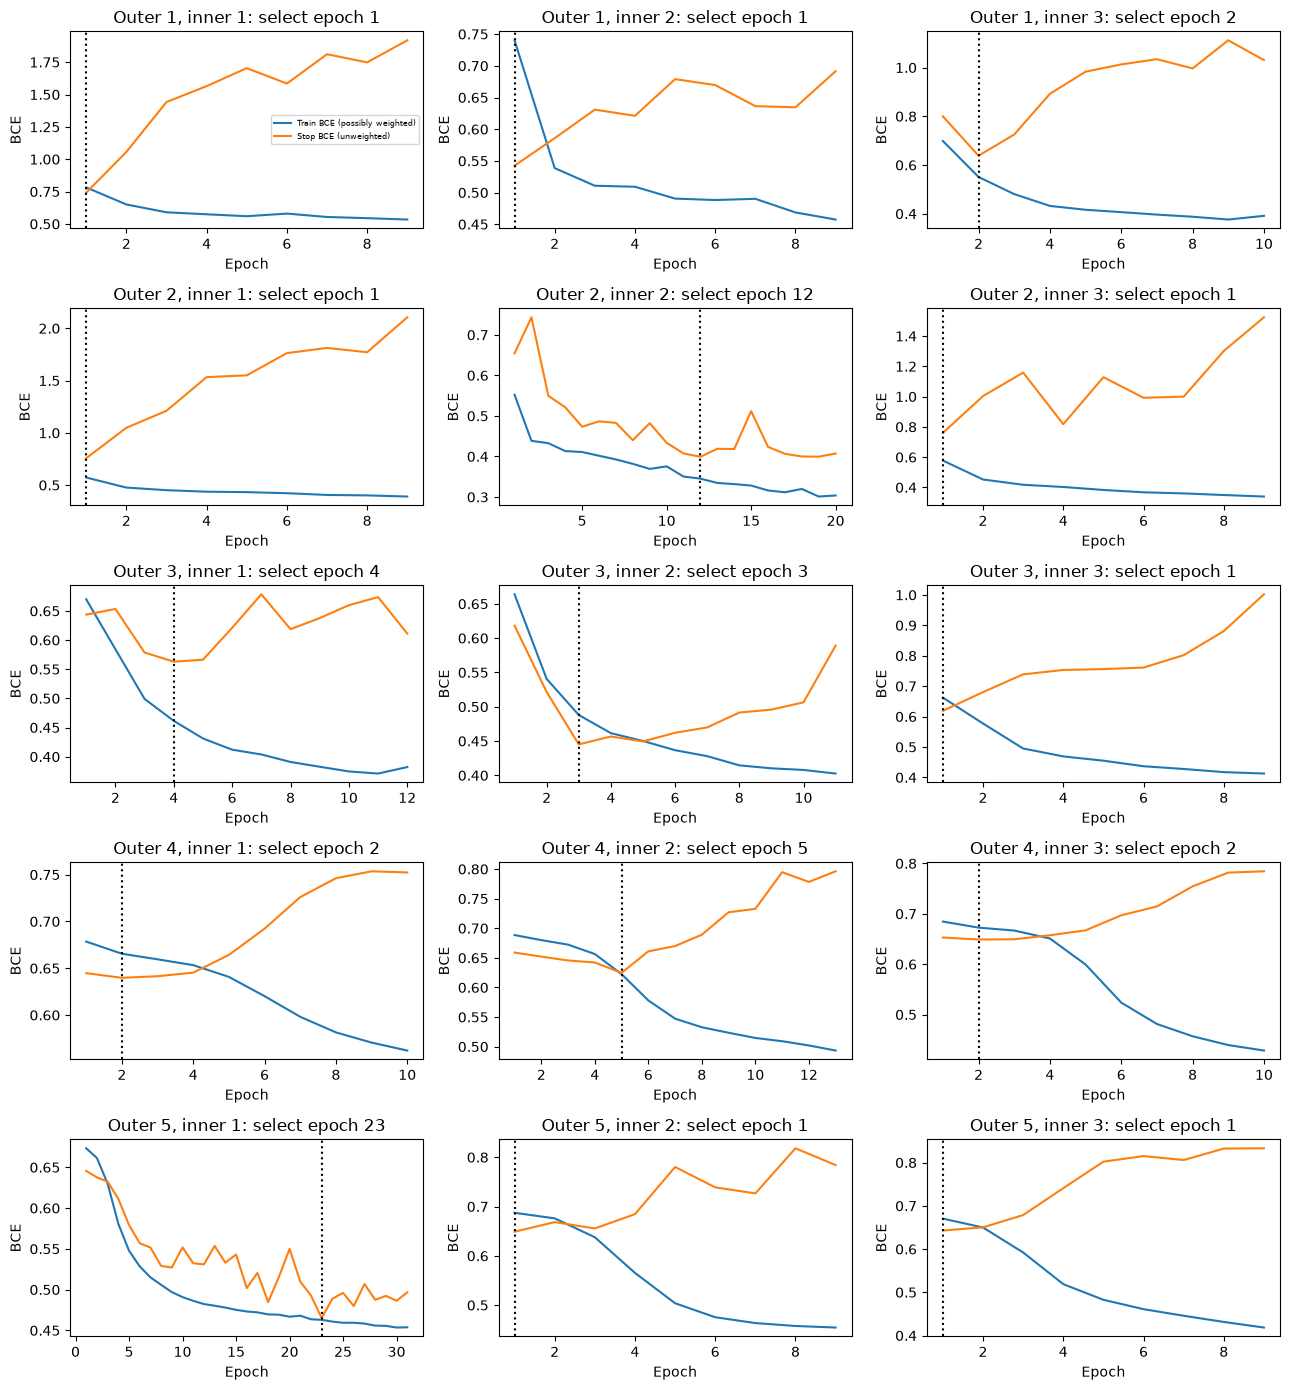

,fold,inner,best_epoch,observed_epochs,first_train,last_train,first_stop,best_stop,last_stop,refit_first,refit_last,pos_weight,stopped_by_patience
0,1,1,1,9,0.781963,0.534010,0.741601,0.741601,1.918875,0.719223,0.719223,1.552760,True
1,1,2,1,9,0.740257,0.457481,0.542472,0.542472,0.691528,0.710510,0.710510,1.480602,True
2,1,3,2,10,0.698635,0.391460,0.799779,0.638170,1.030699,0.716752,0.588078,1.164156,True
3,2,1,1,9,0.572796,0.391005,0.757507,0.757507,2.105561,0.579274,0.579274,1.000000,True
4,2,2,12,20,0.552103,0.303747,0.654369,0.399303,0.407208,0.542454,0.324997,1.000000,True
5,2,3,1,9,0.577330,0.339664,0.760055,0.760055,1.523894,0.574653,0.574653,1.000000,True
6,3,1,4,12,0.669929,0.382179,0.643695,0.562938,0.611135,0.657546,0.480727,1.000000,True
7,3,2,3,11,0.663899,0.402662,0.618172,0.445152,0.589063,0.658396,0.469891,1.000000,True
8,3,3,1,9,0.662368,0.412763,0.618883,0.618883,1.001919,0.651950,0.651950,1.000000,True
9,4,1,2,10,0.678508,0.562121,0.644770,0.639794,0.752349,0.669923,0.658609,1.000000,True


,fold,epochs,first_loss,last_loss
0,1,1,0.698008,0.698008
1,2,1,0.541989,0.541989
2,3,3,0.636700,0.493642
3,4,2,0.672783,0.664942
4,5,1,0.666179,0.666179


In [2]:
curve_rows = []
fig, axes = plt.subplots(5, 3, figsize=(13, 14), sharex=False)
for choice in selected.itertuples():
    outer = int(choice.outer_fold)
    for inner, selected_epoch in enumerate(choice.calibrated_epochs):
        task = f"outer-{outer}/tuned/cnn/candidate-{int(choice.candidate):02d}-inner-{inner}"
        cal = history[history.task.eq(task) & history.stage.eq("calibration")].sort_values("epoch")
        refit = history[history.task.eq(task) & history.stage.eq("refit")].sort_values("epoch")
        assert len(cal) and len(refit) == selected_epoch
        best, stale, best_epoch = np.inf, 0, None
        for row in cal.itertuples():
            if row.stop_loss < best - 0.0001:
                best, stale, best_epoch = row.stop_loss, 0, row.epoch
            else:
                stale += 1
            if stale >= 8:
                assert row.epoch == cal.epoch.max()
        assert best_epoch == selected_epoch
        curve_rows.append(
            dict(
                fold=outer + 1,
                inner=inner + 1,
                best_epoch=best_epoch,
                observed_epochs=len(cal),
                first_train=cal.train_loss.iloc[0],
                last_train=cal.train_loss.iloc[-1],
                first_stop=cal.stop_loss.iloc[0],
                best_stop=best,
                last_stop=cal.stop_loss.iloc[-1],
                refit_first=refit.train_loss.iloc[0],
                refit_last=refit.train_loss.iloc[-1],
                pos_weight=cal.pos_weight.iloc[0],
                stopped_by_patience=stale >= 8,
            )
        )
        ax = axes[outer, inner]
        ax.plot(cal.epoch, cal.train_loss, label="Train BCE (possibly weighted)")
        ax.plot(cal.epoch, cal.stop_loss, label="Stop BCE (unweighted)")
        ax.axvline(best_epoch, color="black", linestyle=":")
        ax.set(
            title=f"Outer {outer + 1}, inner {inner + 1}: select epoch {best_epoch}",
            xlabel="Epoch",
            ylabel="BCE",
        )
axes[0, 0].legend(fontsize=6)
fig.tight_layout()
fig.savefig(OUT / "selected_calibration_curves.png", dpi=150)
plt.show()
curves = pd.DataFrame(curve_rows)
display(curves)
outer_rows = []
for choice in selected.itertuples():
    part = history[history.task.eq(f"outer-{choice.outer_fold}/tuned/cnn/seed-67/outer")]
    assert len(part) == choice.outer_epochs
    outer_rows.append(
        dict(
            fold=choice.outer_fold + 1,
            epochs=len(part),
            first_loss=part.train_loss.iloc[0],
            last_loss=part.train_loss.iloc[-1],
        )
    )
outer_training = pd.DataFrame(outer_rows)
display(outer_training)

## Identify all near-flat minutes from saved filtered waveforms

The diagnostic cutoff is the already-used normalization floor of 0.001 mV, not a new exclusion criterion. Preserve all minutes. Quality flags describe the original retained cohort.

In [3]:
near = []
for record, part in cohort.groupby("record_id"):
    with np.load(PHASE1 / "waveforms" / f"{record}.npz") as source:
        filtered_signal = source["filtered"]
        for row in part.itertuples():
            values = filtered_signal[row.start_sample : row.end_sample]
            if values.std() < 0.001:
                near.append(
                    dict(
                        record_id=record,
                        minute=row.minute,
                        label=row.label,
                        start_sample=row.start_sample,
                        end_sample=row.end_sample,
                        filtered_std=float(values.std()),
                    )
                )
near = pd.DataFrame(near)
assert len(near) == 17
flag_columns = [
    "record_id",
    "minute",
    "quality_flag",
    "flat_signal",
    "low_amplitude",
    "too_few_rr",
    "suspect_rr",
    "filter_edge",
]
near = near.merge(windows[flag_columns], on=["record_id", "minute"], validate="one_to_one")
display(near)

,record_id,minute,label,start_sample,end_sample,filtered_std,quality_flag,flat_signal,low_amplitude,too_few_rr,suspect_rr,filter_edge
0,a17,365,1,2190000,2196000,4.943978e-04,True,True,True,True,False,False
1,b04,5,0,30000,36000,1.129921e-05,True,True,True,True,False,False
2,b04,6,0,36000,42000,1.019989e-10,True,True,True,True,False,False
3,c01,6,0,36000,42000,1.497545e-29,True,True,True,True,False,False
4,c01,7,0,42000,48000,3.154134e-33,True,True,True,True,False,False
5,c02,5,0,30000,36000,9.507354e-06,True,True,True,True,False,False
6,c02,6,0,36000,42000,5.984211e-37,True,True,True,True,False,False
7,c02,7,0,42000,48000,4.638091e-47,True,True,True,True,False,False
8,c02,8,0,48000,54000,8.256674e-16,True,True,True,True,False,False
9,c04,15,0,90000,96000,4.990490e-32,True,True,True,True,False,False


## Verify raw files and reproduce whole-record filtering

Read original digital and physical WFDB samples. Verify dat/header/annotation files against the saved Phase 1 source checksums. Compare saved raw mV arrays with WFDB decoding, then independently run the configured whole-record zero-phase Butterworth filter. Record-level filtering must not be replaced by minute-level filtering in this comparison. Check source annotation alignment as well as raw constancy and digital ranges.

Constant digital samples imply information absent in the source recording; bandpass removal of a constant baseline is expected. Near-zero filtered values alone cannot distinguish source dropout from excessive filtering.

In [4]:
traces = {}
raw_rows = []
filter_rows = []
sos = butter(
    config["filter_order"],
    [config["low_hz"], config["high_hz"]],
    btype="bandpass",
    fs=config["fs"],
    output="sos",
)
for record, part in near.groupby("record_id"):
    for suffix in ["dat", "hea", "apn"]:
        name = f"{record}.{suffix}"
        assert (
            hashlib.sha256((RAW / name).read_bytes()).hexdigest() == phase1["source_sha256"][name]
        )
    physical = wfdb.rdrecord(str(RAW / record))
    digital = wfdb.rdrecord(str(RAW / record), physical=False)
    annotations = wfdb.rdann(str(RAW / record), "apn")
    assert physical.fs == 100
    with np.load(PHASE1 / "waveforms" / f"{record}.npz") as source:
        raw, filtered = source["raw"], source["filtered"]
        np.testing.assert_array_equal(raw, physical.p_signal[:, 0])
        rebuilt = sosfiltfilt(sos, physical.p_signal[:, 0])
        error = float(np.max(np.abs(rebuilt - filtered)))
        np.testing.assert_allclose(rebuilt, filtered, rtol=1e-10, atol=1e-12)
        filter_rows.append(dict(record_id=record, max_filter_error=error))
        traces[record] = (raw.copy(), filtered.copy())
    for row in part.itertuples():
        a, b = row.start_sample, row.end_sample
        raw_minute, dig_minute = raw[a:b], digital.d_signal[a:b, 0]
        label_indices = np.flatnonzero(annotations.sample == a)
        assert len(label_indices) == 1
        symbol = annotations.symbol[label_indices[0]]
        assert int(symbol == "A") == row.label and symbol in {"A", "N"}
        raw_rows.append(
            dict(
                record_id=record,
                minute=row.minute,
                raw_std=float(raw_minute.std()),
                raw_range=float(np.ptp(raw_minute)),
                digital_unique=len(np.unique(dig_minute)),
                digital_min=int(dig_minute.min()),
                digital_max=int(dig_minute.max()),
                annotation=symbol,
                saved_raw_matches=True,
            )
        )
raw_stats = pd.DataFrame(raw_rows)
trace_table = near.merge(raw_stats, on=["record_id", "minute"], validate="one_to_one")
filter_checks = pd.DataFrame(filter_rows)
display(trace_table, filter_checks)

,record_id,minute,label,start_sample,end_sample,filtered_std,quality_flag,flat_signal,low_amplitude,too_few_rr,suspect_rr,filter_edge,raw_std,raw_range,digital_unique,digital_min,digital_max,annotation,saved_raw_matches
0,a17,365,1,2190000,2196000,4.943978e-04,True,True,True,True,False,False,0.0,0.0,1,2047,2047,A,True
1,b04,5,0,30000,36000,1.129921e-05,True,True,True,True,False,False,0.0,0.0,1,0,0,N,True
2,b04,6,0,36000,42000,1.019989e-10,True,True,True,True,False,False,0.0,0.0,1,0,0,N,True
3,c01,6,0,36000,42000,1.497545e-29,True,True,True,True,False,False,0.0,0.0,1,0,0,N,True
4,c01,7,0,42000,48000,3.154134e-33,True,True,True,True,False,False,0.0,0.0,1,0,0,N,True
5,c02,5,0,30000,36000,9.507354e-06,True,True,True,True,False,False,0.0,0.0,1,0,0,N,True
6,c02,6,0,36000,42000,5.984211e-37,True,True,True,True,False,False,0.0,0.0,1,0,0,N,True
7,c02,7,0,42000,48000,4.638091e-47,True,True,True,True,False,False,0.0,0.0,1,0,0,N,True
8,c02,8,0,48000,54000,8.256674e-16,True,True,True,True,False,False,0.0,0.0,1,0,0,N,True
9,c04,15,0,90000,96000,4.990490e-32,True,True,True,True,False,False,0.0,0.0,1,0,0,N,True


,record_id,max_filter_error
0,a17,0.0
1,b04,0.0
2,c01,0.0
3,c02,0.0
4,c04,0.0
5,c09,0.0
6,c10,0.0


## Raw and filtered context plots

Each panel shows the flagged minute and one neighboring minute on either side when available, in physical mV. The shaded region is the near-flat minute. Plots use every sample. Constant source segments may appear at a nonzero baseline; removal of that baseline is not itself a filter error. Displaying context helps distinguish a recording interruption from normal low-amplitude ECG.

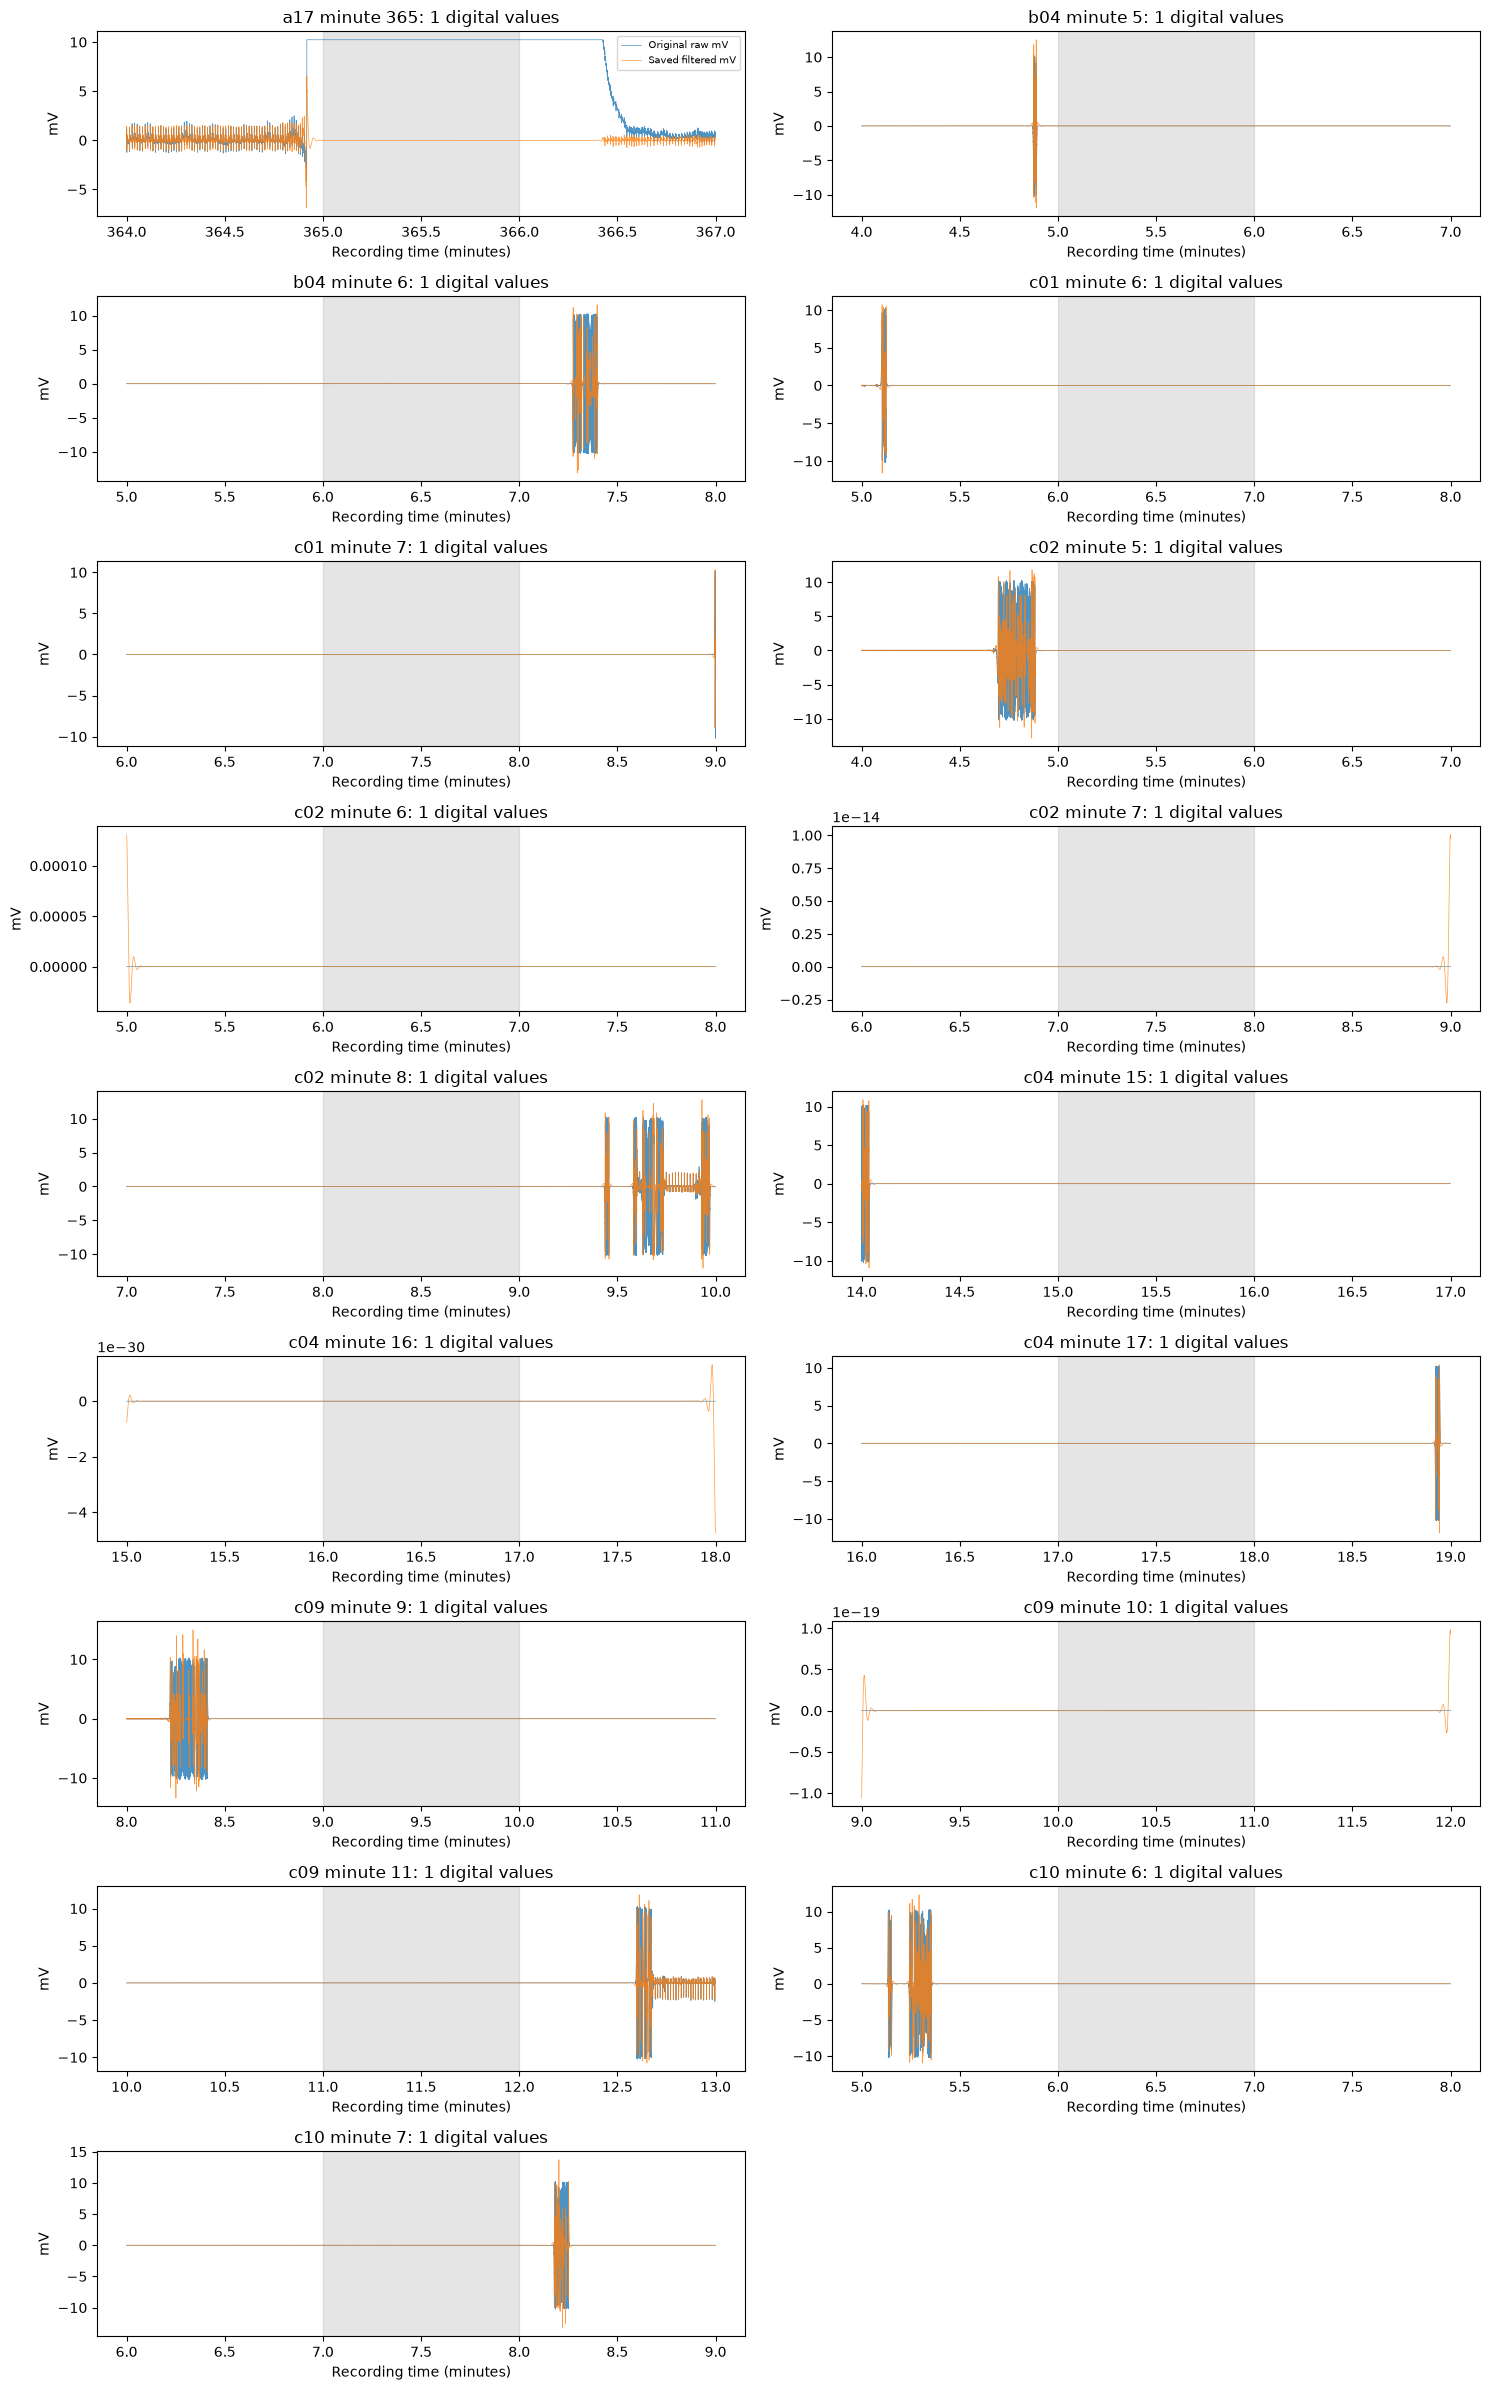

Diagnostic exports: <project-root>/reports/portfolio-v2/cnn-curves-raw/20261110T025126662499Z


In [5]:
fig, axes = plt.subplots(9, 2, figsize=(15, 24))
for ax, row in zip(axes.flat, trace_table.itertuples(), strict=False):
    raw, filtered = traces[row.record_id]
    a, b = max(0, row.start_sample - 6000), min(len(raw), row.end_sample + 6000)
    t = np.arange(a, b) / 100 / 60
    ax.plot(t, raw[a:b], label="Original raw mV", linewidth=0.5, alpha=0.8)
    ax.plot(t, filtered[a:b], label="Saved filtered mV", linewidth=0.5, alpha=0.8)
    ax.axvspan(row.minute, row.minute + 1, alpha=0.2, color="gray")
    ax.set(
        title=f"{row.record_id} minute {row.minute}: {row.digital_unique} digital values",
        xlabel="Recording time (minutes)",
        ylabel="mV",
    )
axes.flat[-1].set_visible(False)
axes.flat[0].legend(fontsize=7)
fig.tight_layout()
fig.savefig(OUT / "near_flat_raw_context.png", dpi=120)
plt.show()
for name, table in {
    "selected_curves": curves,
    "outer_training": outer_training,
    "near_flat_trace": trace_table,
    "filter_reconstruction": filter_checks,
}.items():
    table.to_csv(OUT / f"{name}.csv", index=False)
print("Diagnostic exports:", OUT)